# Run the benchmark

The benchmark asks one question: **how well does a cell's own H&E crop predict its expression?**
This tutorial runs the offline demo, checks the published numbers, and shows how to replay or
refit a frozen fold once you have the benchmark package. Steps 1–3 need no data and no GPU.

> **Requirements.** A clone of the code repository and `pip install -r benchmark/requirements-cpu.txt` (Python 3.10 is the reference runtime).

In [1]:
import json, subprocess, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# the repository root (works from the repo or from website/tutorials)
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "benchmark/smcc_benchmark.py").exists())
BENCH = [sys.executable, str(REPO / "benchmark/smcc_benchmark.py")]

def run(*args):
    out = subprocess.run([*BENCH, *args], capture_output=True, text=True, check=True).stdout
    return json.loads(out) if out.strip().startswith(("{", "[")) else out

## 1. The protocol tracks

In [2]:
tracks = pd.DataFrame(run("list"))
tracks[["track", "platform", "acquisitions", "folds", "reference_prediction_packets", "protocol"]]

,track,platform,acquisitions,folds,reference_prediction_packets,protocol
0,hd18,HD,49,196,196,training-only organ/species/fold HVGs
1,hd_cross,HD,34,174,310,archived fold-specific protocol; see folds/con...
2,xenium5,Xenium,13,52,52,training-only organ/species/fold HVGs
3,xenium_legacy,Xenium,30,120,120,archived fold-specific protocol; see folds/con...
4,xenium_legacy_cross,Xenium,18,54,18,archived fold-specific protocol; see folds/con...


Counts are acquisitions, not patients. Modern (`hd18`, `hd_cross`, `xenium5`) and legacy protocols
are kept apart and never pooled.

## 2. Offline demo

The demo generates synthetic cells and runs the full pipeline: spatial split, training-only target
selection, image-feature regression, controls and metrics. Its scores test the code path; they are
**not** biological results.

In [3]:
subprocess.run([*BENCH, "demo", "--output", "/tmp/smmc-demo"], check=True, capture_output=True)
demo = json.loads(Path("/tmp/smmc-demo/demo.json").read_text())
print(f"{demo['observations']} synthetic cells · {demo['n_train']} train / {demo['n_test']} test · "
      f"{demo['selected_genes']} training-only target genes")

1600 synthetic cells · 1195 train / 320 test · 50 training-only target genes


In [4]:
pd.DataFrame(demo["metrics"]).T[["pearson_gene_macro", "spearman_gene_macro", "pearson_cell_macro",
                                 "f1_gene_macro", "r2_gene_macro"]].round(3)

,pearson_gene_macro,spearman_gene_macro,pearson_cell_macro,f1_gene_macro,r2_gene_macro
train_mean,NaN,NaN,0.011,0.771,-0.005
coordinate,0.006,0.009,0.013,0.759,-0.034
image,0.273,0.259,0.265,0.761,0.071
spatial_knn,-0.001,-0.004,0.000,0.710,-0.132


## 3. Check the published 23-category numbers

`summarize_results.py` recomputes the category-weighted means from the per-category tables shipped
in `results/` and verifies them against the published macro rows.

In [5]:
sys.path.insert(0, str(REPO / "scripts"))
from summarize_results import summarize
rows, means = summarize(REPO)
pd.DataFrame(means).set_index("Category")[["n", "Gene P", "Coord P", "KNN P", "Cell P", "F1", "R²"]].round(3)

,n,Gene P,Coord P,KNN P,Cell P,F1,R²
Category,,,,,,,
18-category HD macro mean,48,0.365,0.051,0.056,0.445,0.411,-0.090
5-category Xenium-only macro mean,13,0.303,0.042,0.061,0.419,0.289,-0.152
23-category macro mean,61,0.351,0.049,0.057,0.439,0.385,-0.103


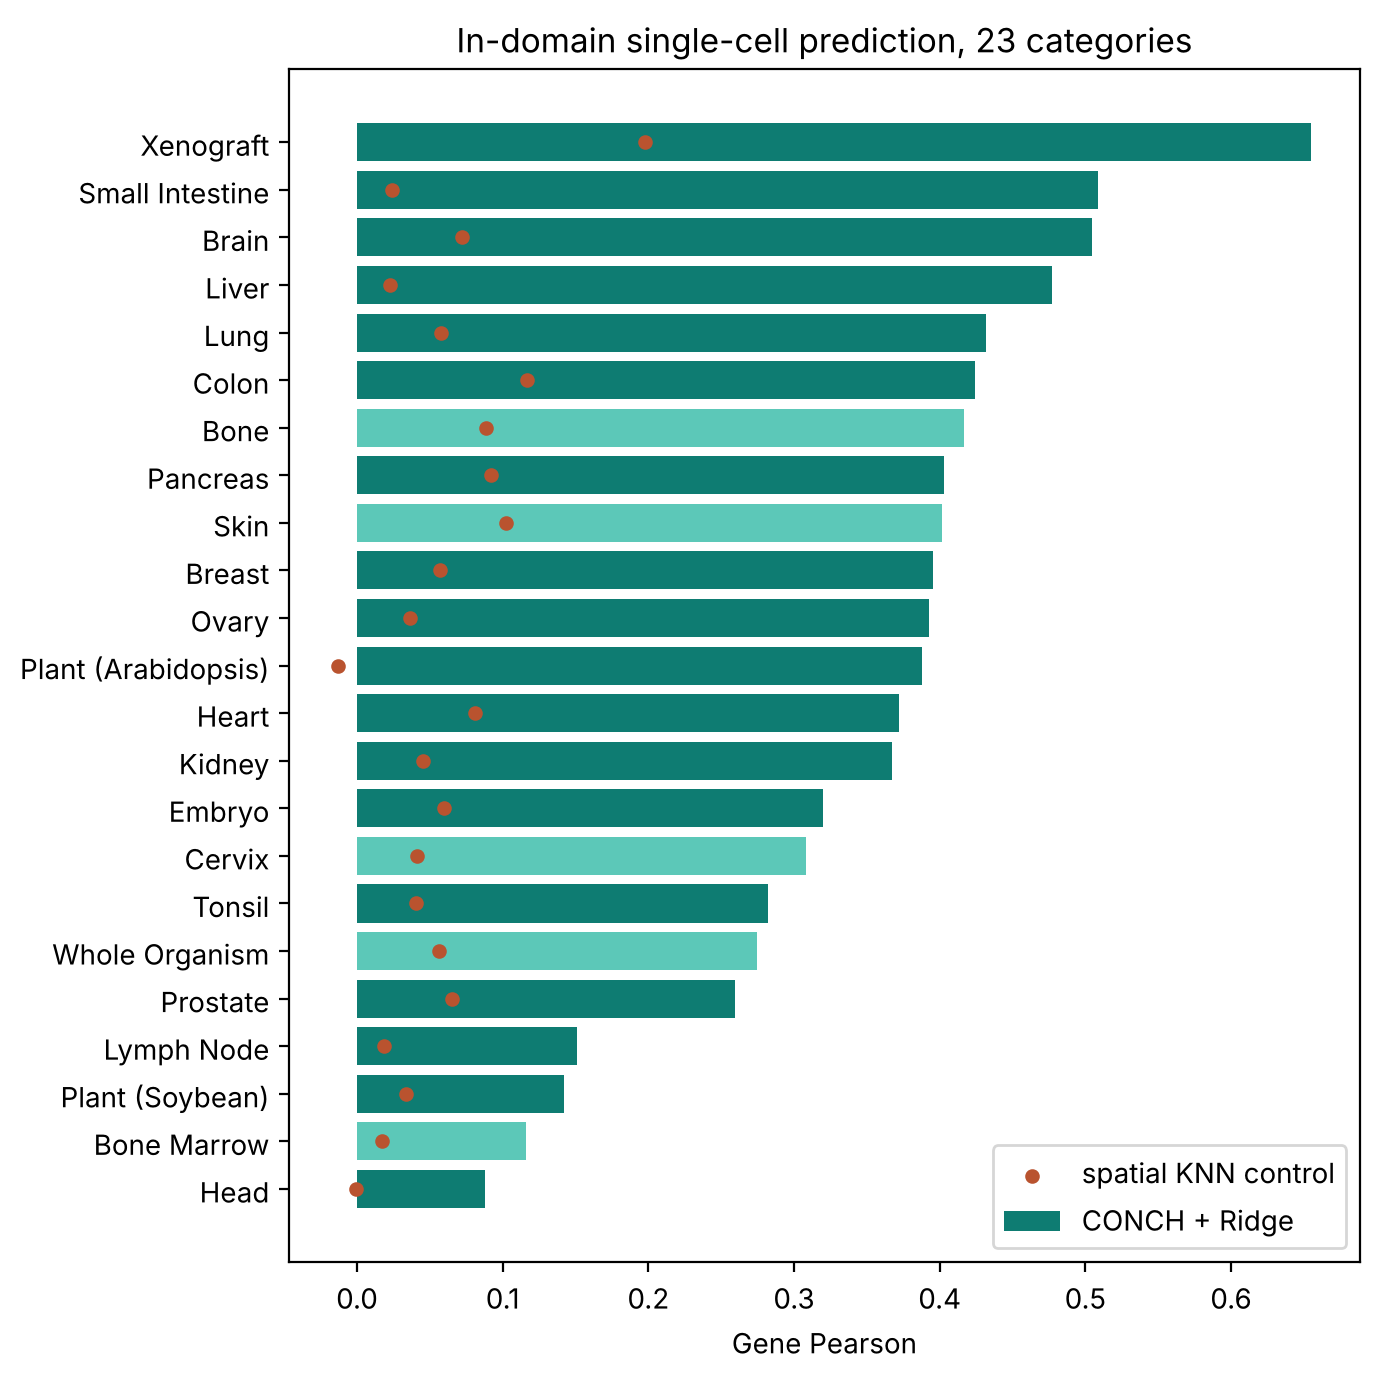

In [6]:
per_cat = pd.DataFrame(rows).astype({"Gene P": float, "Coord P": float, "KNN P": float})
per_cat = per_cat.sort_values("Gene P")
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(per_cat.Category, per_cat["Gene P"], color=["#0e7c72" if d == "Visium HD" else "#5cc8b8" for d in per_cat.Data], label="CONCH + Ridge")
ax.scatter(per_cat["KNN P"], per_cat.Category, color="#b9532f", zorder=3, s=18, label="spatial KNN control")
ax.set_xlabel("Gene Pearson"); ax.legend(loc="lower right"); ax.set_title("In-domain single-cell prediction, 23 categories")
plt.tight_layout(); plt.show()

Dark bars are Visium HD categories, light bars Xenium-only. The image model beats the spatial
control in every category, but R² stays negative: predictions capture relative patterns, not
calibrated magnitudes.

## 4. Within vs across acquisitions

The matched comparison keeps the same held-out cells and genes and changes only where the training
data came from.

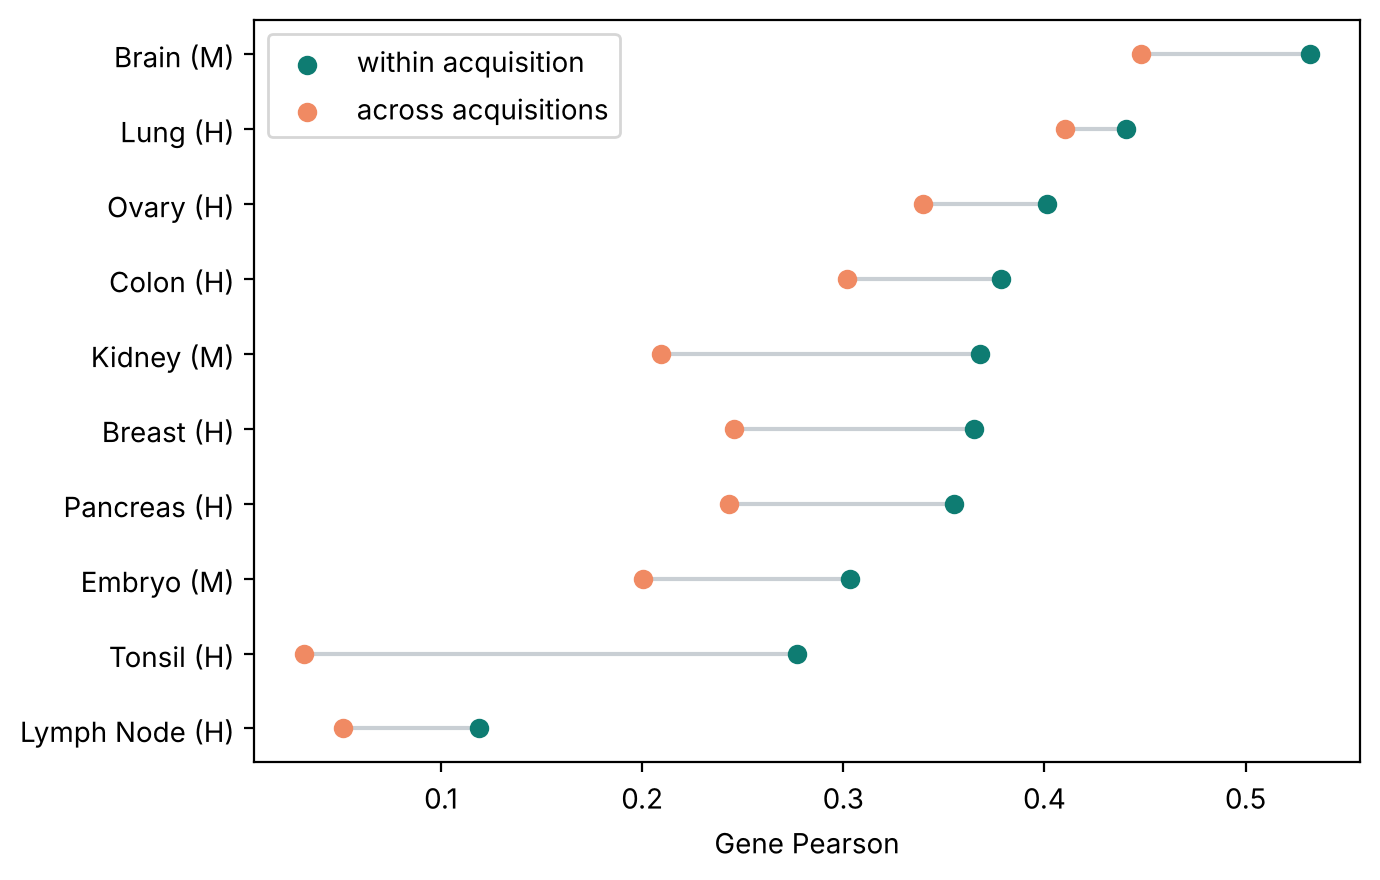

In [7]:
m = pd.read_csv(REPO / "results/hd_cross_matched_by_category.csv")
m = m[m.model == "image"].sort_values("within_pearson_gene_macro")
fig, ax = plt.subplots(figsize=(7, 4.5))
lab = m.organ + " (" + m.species.str[0] + ")"
ax.hlines(lab, m.cross_pearson_gene_macro, m.within_pearson_gene_macro, color="#c9cfd4")
ax.scatter(m.within_pearson_gene_macro, lab, color="#0e7c72", label="within acquisition", zorder=3)
ax.scatter(m.cross_pearson_gene_macro, lab, color="#f08a63", label="across acquisitions", zorder=3)
ax.set_xlabel("Gene Pearson"); ax.legend(); plt.tight_layout(); plt.show()

In [8]:
pd.read_csv(REPO / "results/hd_cross_matched_macro.csv").set_index("model")[
    ["within_pearson_gene_macro", "cross_pearson_gene_macro", "within_pearson_cell_macro", "cross_pearson_cell_macro"]].round(3)

,within_pearson_gene_macro,cross_pearson_gene_macro,within_pearson_cell_macro,cross_pearson_cell_macro
model,,,,
image,0.354,0.248,0.563,0.349
train_mean,NaN,NaN,0.513,0.365


## 5. Replay and refit a frozen fold

These steps need the benchmark package from the
[frozen release](https://huggingface.co/datasets/zhang-lab/sMCC40M/tree/0f6f6577b0da8e00d2624e834aa6efc1c651b1ad/benchmark)
(about 3 GB). Outputs must be written outside the release folder.

```bash
export SMMC_RELEASE_ROOT=/path/to/2026-10-28

# recompute metrics from the original saved predictions (no training)
python benchmark/smcc_benchmark.py replay --track hd18 --sample HD-001 --output /tmp/smmc-replay

# refit PCA + Ridge on exactly the frozen rows and targets from cached CONCH features
python benchmark/smcc_benchmark.py refit --fold hd18_HD-001_seed0 --output /tmp/smmc-refit
```

`replay` checks every metric against the frozen reference within an absolute 5e-5 bound.
`refit` records the numerical environment and new scores; it is not expected to be bitwise identical
to the original run. To regenerate inputs from raw images and RNA (CONCH weights, GPU), see the
[benchmark README](https://github.com/aicb-ZhangLabs/sMMC40M/blob/main/benchmark/README.md).

## Add your model

Keep the frozen splits and training-only targets, replace the image features, and report the same
metrics per acquisition, then per category. Compare against the coordinate and KNN controls, and
report within- and across-acquisition results separately.